In [1]:
from probly.evaluation.active_learning import strategies

print("Verfügbare Query Strategies:")

for name in dir(strategies):
    if not name.startswith("_"):
        print(name)

Verfügbare Query Strategies:
BADGEQuery
BadgeEstimator
EntropySampling
Estimator
LeastConfidentSampling
MarginSampling
QueryStrategy
RandomQuery
TORCH_TENSOR
UncertaintyEstimator
UncertaintyQuery
badge_embed
badge_select
entropy_score
least_confident_score
margin_score
numpy
random_select
topk_select


In [2]:
from probly.evaluation.active_learning import (
    EntropySampling,
    LeastConfidentSampling,
    MarginSampling,
    RandomQuery,
    active_learning_steps,
    from_dataset,
)

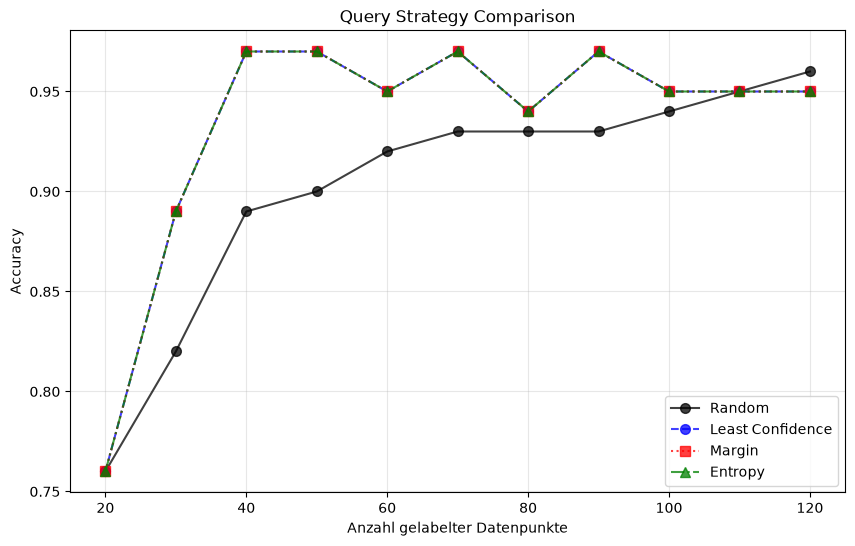

In [10]:
import matplotlib.pyplot as plt
from sklearn.datasets import make_moons
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split

X, y = make_moons(n_samples=500, noise=0.2, random_state=42)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

query_strategies = {
    "Random": RandomQuery(seed=42),
    "Least Confidence": LeastConfidentSampling(),
    "Margin": MarginSampling(),
    "Entropy": EntropySampling(),
}

results = {}

for name, strategy in query_strategies.items():
    pool = from_dataset(X_train, y_train, X_test, y_test, initial_size=20, seed=42)

    model = RandomForestClassifier(n_estimators=100, random_state=42)

    sizes = []
    accuracies = []

    for state in active_learning_steps(pool, model, strategy, query_size=10, n_iterations=10):
        prediction = state.estimator.predict(state.pool.x_test)

        accuracy = accuracy_score(state.pool.y_test, prediction)

        sizes.append(state.pool.n_labeled)
        accuracies.append(accuracy)

    results[name] = (sizes, accuracies)
plt.figure(figsize=(10, 6))

styles = {
    "Random": ("black", "-", "o"),
    "Least Confidence": ("blue", "--", "o"),
    "Margin": ("red", ":", "s"),
    "Entropy": ("green", "-.", "^"),
}

for name, (sizes, accuracies) in results.items():
    color, linestyle, marker = styles[name]

    plt.plot(sizes, accuracies, label=name, color=color, linestyle=linestyle, marker=marker, markersize=7, alpha=0.75)

plt.xlabel("Anzahl gelabelter Datenpunkte")
plt.ylabel("Accuracy")
plt.title("Query Strategy Comparison")
plt.legend()
plt.grid(alpha=0.3)
plt.show()